In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

**DATA**

In [ ]:
''' GEOMETRY & MASS '''
m_curb = 1195 #kg
m_driver = 75 #kg
m = m_curb + m_driver #kg
length = 3.999 #m
width = 1.775 #m
height = 1.597 #m
L = 2.570 #m
b_cg = 0.53*L #m
c_cg = 0.47*L #m
h_cg = 0.47 #m  TO CHECK !!

'''TRANSMISSION & TIRE '''
# 19 inches rim; /39.37 converts inches in meters; 0.7*155 is thickness of tire
D_wheel = (( 19 / 39.37 ) + ( 155 * 0.7 * 2)*10**-3)
eta_t = 0.9875 #-  TO CHECK !!
i_gear = 9.665 #-
f0 = 0.008
f2 = 0.4e-7
R_e = 0.98*(D_wheel/2) #m

''' ENGINE '''
P_1p = 125e3 #W
P_1n = 75e3 #W
C_max = 250 #Nm
omega_b = 4800 * (2*np.pi / 60) #rad/s
E_bat = 22.6e3 #Wh
J_mot = 0.03 #kg m^2  TO CHECK !!

''' OTHER '''
g = 9.81 #m/s**2
rho = 1.23 #kg/m**3
S = 2.38 #m**2
C_x = 0.29 #-

**ROAD RESISTANCE FORCE AND POWER** (computations)

In [ ]:
''' SLOPES '''
theta0 = np.arctan(0) #°
theta5 = np.arctan(0.05) #°
theta10 = np.arctan(0.1) #°

''' SPEED VECTORS '''
v_kmh = np.linspace(0,150,11400) #km/h; 150 is max speed given in litterature
v_ms = v_kmh/3.6

''' GRADING '''
F_grading0 = m*g*np.sin(theta0)
F_grading5 = m*g*np.sin(theta5)
F_grading10 = m*g*np.sin(theta10)

P_grading0 = F_grading0 * v_ms
P_grading5 = F_grading5 * v_ms
P_grading10 = F_grading10 * v_ms

''' AERODYNAMIC DRAG '''
F_AERO = 0.5*rho*S*C_x*(v_ms**2)
P_AERO = F_AERO * v_ms

''' ROLLING RESISTANCE '''
F_RR0  = m*g*(f0 + f2*(v_kmh**2))*np.cos(theta0)
F_RR5  = m*g*(f0 + f2*(v_kmh**2))*np.cos(theta5)
F_RR10 = m*g*(f0 + f2*(v_kmh**2))*np.cos(theta10)

P_RR0  = F_RR0 * v_ms
P_RR5  = F_RR5 * v_ms
P_RR10 = F_RR10 * v_ms

''' TOTAL '''
F_RES0 = F_grading0 + F_AERO + F_RR0
F_RES5 = F_grading5 + F_AERO + F_RR5
F_RES10 = F_grading10 + F_AERO + F_RR10

P_RES0 = P_grading0 + P_AERO + P_RR0
P_RES5 = P_grading5 + P_AERO + P_RR5
P_RES10 = P_grading10 + P_AERO + P_RR10


**ROAD RESISTANCE FORCE AND POWER** (plots)

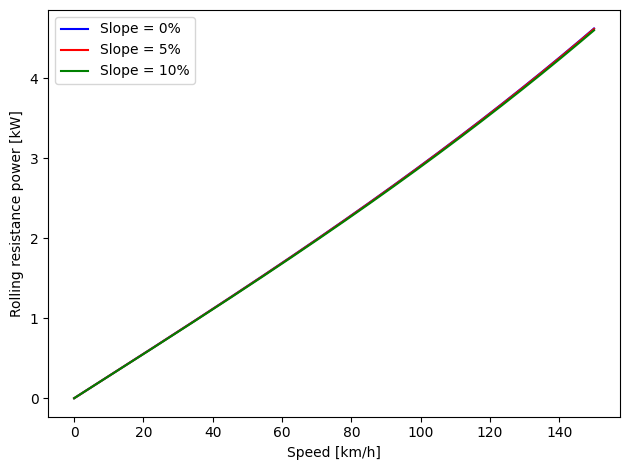

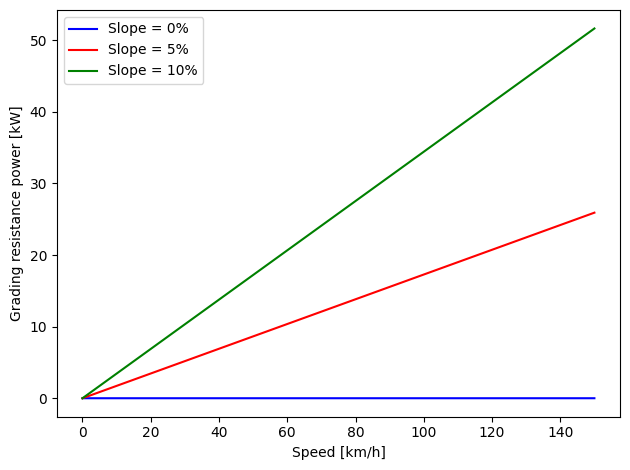

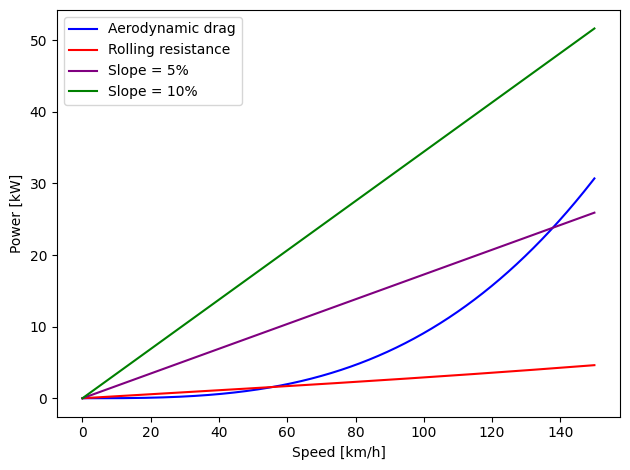

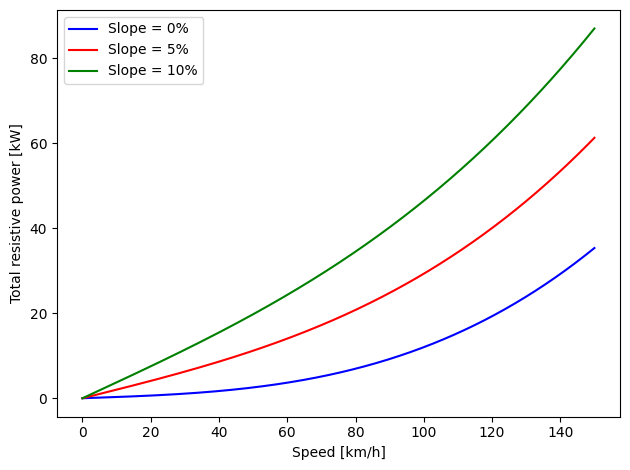

In [ ]:
''' ROLLING RESISTANCE '''
plt.figure()
plt.plot(v_kmh, P_RR0*10**-3, label='Slope = 0%', color = 'blue')
plt.plot(v_kmh, P_RR5*10**-3, label='Slope = 5%', color = 'red')
plt.plot(v_kmh, P_RR10*10**-3, label='Slope = 10%', color = 'green')
plt.xlabel('Speed [km/h]')
plt.ylabel('Rolling resistance power [kW]')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

''' GRADING '''
plt.figure()
plt.plot(v_kmh, P_grading0*10**-3, label='Slope = 0%', color = 'blue')
plt.plot(v_kmh, P_grading5*10**-3, label='Slope = 5%', color = 'red')
plt.plot(v_kmh, P_grading10*10**-3, label='Slope = 10%', color = 'green')
plt.xlabel('Speed [km/h]')
plt.ylabel('Grading resistance power [kW]')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

''' 3 CONTRIBUTIONS '''
plt.figure()
plt.plot(v_kmh, P_AERO*10**-3, label='Aerodynamic drag', color = 'blue')
plt.plot(v_kmh, P_RR0*10**-3, label='Rolling resistance', color = 'red')
plt.plot(v_kmh, P_grading5*10**-3, label='Slope = 5%', color = 'purple')
plt.plot(v_kmh, P_grading10*10**-3, label='Slope = 10%', color = 'green')
plt.xlabel('Speed [km/h]')
plt.ylabel('Power [kW]')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

''' TOTAL '''
plt.figure()
plt.plot(v_kmh, P_RES0*10**-3, label='Slope = 0%', color = 'blue')
plt.plot(v_kmh, P_RES5*10**-3, label='Slope = 5%', color = 'red')
plt.plot(v_kmh, P_RES10*10**-3, label='Slope = 10%', color = 'green')
plt.xlabel('Speed [km/h]')
plt.ylabel('Total resistive power [kW]')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

**MOTOR CURVES** (computations)

In [ ]:
omega = np.linspace(1*(2*np.pi)/60, 11400*(2*np.pi)/60, 11400)
rpm = omega*60/(2*np.pi)

P_peak = np.zeros_like(omega)
C_peak = np.zeros_like(omega)
P_nom = np.zeros_like(omega)
C_nom = np.zeros_like(omega)

# Before reaching base rotation speed, torque is constant at maximum value, then
# the power becomes constant after base rotation speed
for i in range(len(omega)):
  if omega[i] <= (P_1p/C_max):
    P_peak[i] = C_max*omega[i]
  else:
    P_peak[i] = P_1p
C_peak = P_peak/omega

# The base speed should be kept beween nominal & peak regimes, so a new torque
# value should be determined by knowing omega_b
C_max_nom = P_1n/omega_b
for j in range(len(omega)):
  if omega[j] <= (P_1n/C_max_nom):
    P_nom[j] = C_max_nom*omega[j]
  else:
    P_nom[j] = P_1n
C_nom = P_nom/omega

# For the next steps, it is more consistent to use nominal regime rather than
# peak one. However, sometimes the 2 of them will be compared

**MOTOR CURVES** (plots)

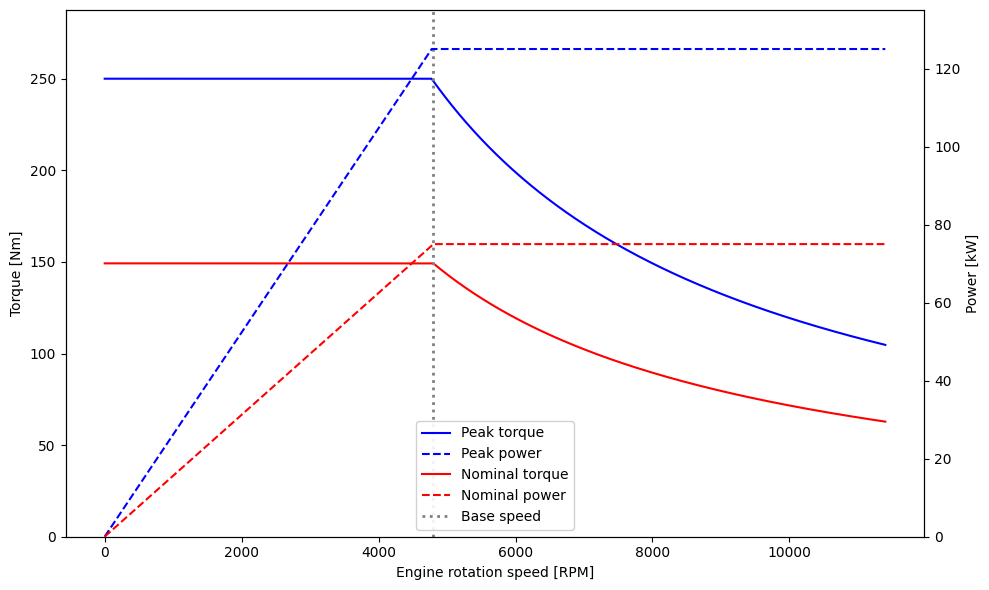

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Left axis : Torques
line1 = ax1.plot(rpm, C_peak, label='Peak torque', color='blue')
line1b = ax1.plot(rpm, C_nom, label='Nominal torque', color='red')
ax1.set_xlabel('Engine rotation speed [RPM]')
ax1.set_ylabel('Torque [Nm]')
ax1.tick_params(axis='y')

# Right axis : Powers
ax2 = ax1.twinx()
line2 = ax2.plot(rpm, P_peak*10**-3, linestyle='--', label='Peak power', color='blue')
line2b = ax2.plot(rpm, P_nom*10**-3, linestyle='--', label='Nominal power', color='red')
ax2.set_ylabel('Power [kW]')
ax2.tick_params(axis='y')
ax2.grid(False) # Either 2 grids mixed, awful

# Scaling
ax1.set_ylim(0, C_max * 1.15)
ax2.set_ylim(0, (P_1p*10**-3) * 1.08)

# Base speed
rpm_base_peak = omega_b * 60 / (2 * np.pi)
line3 = ax1.axvline(x=rpm_base_peak, color='gray', linestyle=':', linewidth=2, label=f'Base speed')

# Legend
lines = line1 + line2 + line1b + line2b + [line3]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='lower center', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

**TRACTIVE FORCE & ACCELERATION CAPABILITY** (computations)

In [ ]:
''' TRACTIVE FORCES'''
# Speed vector corresponding to the whole range of motor rotation speed
v_ms_t = (omega*R_e)/i_gear
v_kmh_t = v_ms_t*3.6

# Traction force and power
F_t = (eta_t * C_nom * i_gear)/R_e
P_t = F_t * v_ms

''' NET FORCES'''
F_net = F_t - F_RES0
P_net = P_t - P_RES0

'''ACCELERATION CAPABILITY'''
m_e = m_curb*(1.04 + (J_mot/(m_curb*R_e**2))*i_gear**2) #effective mass
accel_capa = m_e/F_net

**TRACTIVE FORCE & ACCELERATION CAPABILITY** (plots)

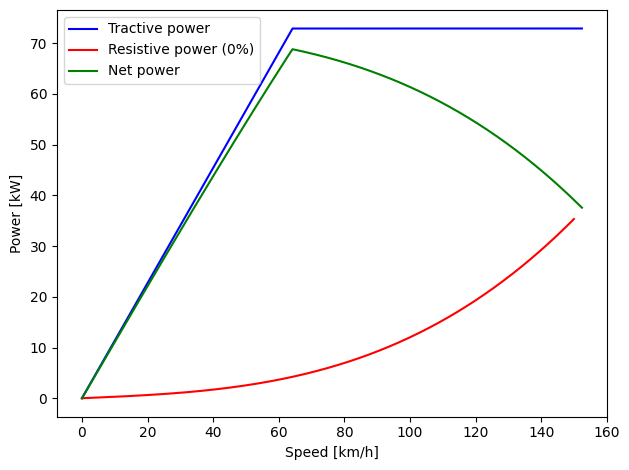

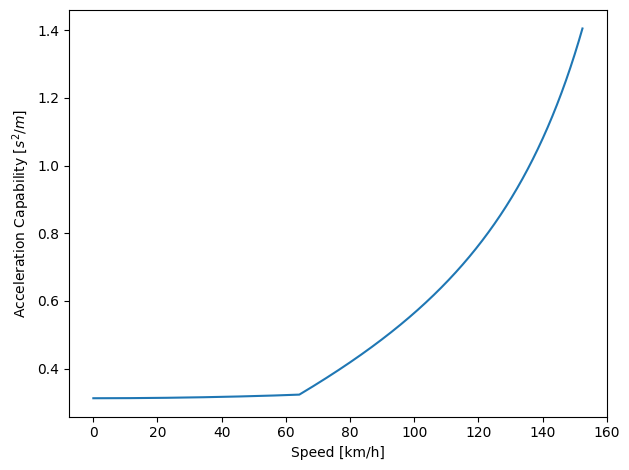

In [ ]:
plt.figure()
plt.plot(v_kmh_t, P_t*10**-3, label='Tractive power', color='blue')
plt.plot(v_kmh, P_RES0*10**-3, label='Resistive power (0%)', color='red')
plt.plot(v_kmh_t, P_net*10**-3, label='Net power', color='green')
plt.xlabel('Speed [km/h]')
plt.ylabel('Power [kW]')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

#Acceleration capability
plt.figure()
plt.plot(v_kmh_t, accel_capa)
plt.xlabel('Speed [km/h]')
plt.ylabel('Acceleration Capability [$s^2/m$]')
plt.tight_layout()
plt.show()

**TOP SPEED**

In [ ]:
''' MAXIMUM THEORETICAL SPEED'''
max_iter = 100
tol = 1e-4
v_0 = 1 # arbitrary choice
A_v = (m*g*np.sin(theta0)) + (m*g*f0*np.cos(theta0))
B_v = (0.5 * rho * S * C_x) + (m*g*(f2/12.96)*np.cos(theta0))

# Computation of v_max_max and ideal gear ratio
i=0
for i in range(max_iter):
  if i==0:
    v_next = ( ((eta_t * P_1n) - (A_v * v_0)) / B_v )**(1/3)
    v_act = v_next

  else :
    v_next = ( ((eta_t * P_1n) - (A_v * v_act)) / B_v )**(1/3)

    if (np.abs(v_next - v_act) < tol ) :
      break
    else:
      v_act = v_next

v_max_max = v_next
print("Theorical greatest maximum speed: ", v_max_max * 3.6, "km/h")

ideal_i = ((omega_b) * R_e) / v_max_max
print("Ideal gear ratio to reach v_max_max: ", ideal_i)

''' MAXIMUM SPEED WITH IMPOSED GEAR RATIO'''
v_act_bis = v_0
for k in range(max_iter):
    omega_max = 11400*(2*np.pi)/60
    omega_k = min(v_act_bis*i_gear/R_e, omega_max)
    P_k = eta_t * min(C_max_nom*omega_k, P_1n)

    v_new = ((P_k - (A_v * v_act_bis)) / B_v) ** (1/3)

    if abs(v_new - v_act_bis) < tol:
        break
    v_act_bis = v_new
v_power = v_new
v_rpm = ((11400 * (2*np.pi) / 60) * R_e) / i_gear
v_max = min(v_rpm, v_power)

print(f"Real greatest maximum speed: {v_max*3.6:.2f} km/h")

Theorical greatest maximum speed:  196.11760578260842 km/h
Ideal gear ratio to reach v_max_max:  3.1630222972233963
Real greatest maximum speed: 152.43 km/h


**MAXIMUM SLOPE**

In [ ]:
mu = 1 # choice
print("mu=",mu)

'''MAXIMUM SLOPE IN FIRST GEAR FROM STANSTILL'''
max_slope1 = 100 * ( ((mu * b_cg / L) - f0) / ( 1 - (mu * h_cg / L) ) )
print("Maximum slope in 1st gear : ",max_slope1, "%")

'''MAXIMUM SLOPE AT 80 KM/H '''
F_t_80 = np.interp(80, v_kmh_t, F_t) #need to obtain the value for the exact 80kph speed
F_aero80 = 0.5*rho*S*C_x*(80/3.6)**2
d_80 = (F_t_80 - F_aero80) / (m*g)
max_slope80 = 100 * np.tan( np.asin( (d_80 - (f0 * np.sqrt(1 + f0**2 - d_80**2))) / (1 + f0**2) ) )
print("Maximum slope at 80 km/h ",max_slope80, "%")

# VERIFICATION OF TRACTION-LIMITED SLOPE
a = (m*g*(f0+(f2*80**2))) - (mu * m * g * c_cg/L)
b = (m*g) + (mu * m * g * h_cg/L)
max_slope80_adhesion = 100 * np.tan(np.asin(-F_aero80/(np.sqrt(a**2 + b**2))) - np.asin(a/(np.sqrt(a**2 + b**2))))
print("Verification que la limite de traction est plus grande que la puissance : ", max_slope80_adhesion, "> 25% => ok")

mu= 1
Maximum slope in 1st gear :  63.88285714285714 %
Maximum slope at 80 km/h  25.042496640538854 %
Verification que la limite de traction est plus grande que la puissance :  37.51642342289927 > 25% => ok


**ACCELERATION & ELASTICITY **

In [ ]:
''' 50 TO 90 km/h'''
v_50_90 = np.linspace(50/3.6, 90/3.6, 100)
F_net_50_90 = np.interp(v_50_90*3.6, v_kmh_t, F_net)
integral_50_90 = np.trapezoid(1/F_net_50_90,v_50_90)
time_50_90 = m_e * integral_50_90
print("Acceleration time to go from 50 km/h to 90 km/h :", time_50_90, "s")

'''0 TO 100 km/h'''
v_0_100 = np.linspace(1/3.6, 100/3.6, 100)
F_net_0_100 = np.interp(v_0_100*3.6, v_kmh_t, F_net)
integral_0_100 = np.trapezoid(1/F_net_0_100,v_0_100)
time_0_100 = m_e * integral_0_100
print("Acceleration time to go from 0 km/h to 100 km/h :", time_0_100, "s")

'''0 TO 400m'''
#aucune idee de v_finale => d'abord calculer temps et distance pour 0-150. Si en dessous de 400m =>
#imposer vitesse constante 150km/h pour derniers metres. Sinon, interpoler avant 150km/h
v_0_150 = np.linspace(1/3.6, 150/3.6, 1000)
F_net_0_150 = np.interp(v_0_150 * 3.6, v_kmh_t, F_net)
time_cumul = m_e * cumulative_trapezoid(1 / F_net_0_150, v_0_150)
dist_cumul = m_e * cumulative_trapezoid(v_0_150 / F_net_0_150, v_0_150)# pour stocker les valeurs dans un vecteur, utile
# pour interpoler après s'il faut
dist_150 = dist_cumul[-1]
time_150 = time_cumul[-1]

if dist_150 >= 400:
    time_400m = np.interp(400, dist_cumul, time_cumul)
    v_400m_kmh = np.interp(400, dist_cumul, v_0_150 * 3.6)
else:
    dist_restante = 400 - dist_150
    time_400m = time_150 + (dist_restante / (150/3.6))
    v_400m_kmh = 150

print("Acceleration time for 0 to 400m :", time_400m, "s")
print("Speed at 400m :", v_400m_kmh, "km/h")

Acceleration time to go from 50 km/h to 90 km/h : 4.143269486125176 s
Acceleration time to go from 0 km/h to 100 km/h : 9.88200754662788 s
Acceleration time for 0 to 400m : 17.367337299723232 s
Speed at 400m : 135.8054572946042 km/h
